# CPM PROJECT MANAGEMENT

The Critical Path Method (CPM) calculates project duration based on the provided input and identifies the critical path. It provides the following functionality:

activities: A list of activity names.

optimistic: A list of optimistic durations for each activity.

likely: A list of likely durations for each activity.

pessimistic: A list of pessimistic durations for each activity.

predecessor: A list of predecessors for each activity, separated by commas. Use '-' for activities with no predecessors

In [1]:
activities = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']
optimistic = [135, 160, 15, 105, 100, 40, 30, 140, 110, 85]
likely = [150, 180, 30, 120, 120, 60, 60, 150, 120, 90]
pessimistic = [180, 220, 45, 140, 135, 70, 75, 185, 145, 125]
predecessor = ['-', '-', 'b', 'c', 'a,c', 'd', 'e,f', 'd', 'h', 'i']

# install libraries 

In [2]:
import pandas as pd
import numpy as np
import math
from pert import PERT
import matplotlib.pyplot as plt
import networkx as nx

# Create a DataFrame of Input

In [3]:
data = {'Activity': activities,
        'Optimistic_a':optimistic,
        'Most_likely_m':likely,
        'Pessimistic_b':pessimistic,
        'Predecessor':predecessor}
df_pm = pd.DataFrame(data)
df_pm

,Activity,Optimistic_a,Most_likely_m,Pessimistic_b,Predecessor
0,a,135,150,180,-
1,b,160,180,220,-
2,c,15,30,45,b
3,d,105,120,140,c
4,e,100,120,135,"a,c"
5,f,40,60,70,d
6,g,30,60,75,"e,f"
7,h,140,150,185,d
8,i,110,120,145,h
9,j,85,90,125,i


# Calculate Project Duration

The estimated duration (Estimate) for each activity is calculated using the PERT formula:
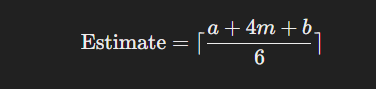

Optimistic Time (a):Represents the shortest possible time to complete an activity.

Most Likely Time (m):Represents the most realistic time estimate based on normal conditions and typical performance.

Pessimistic Time (b):Represents the longest possible time to complete an activity.

Project Duration: 708
Critical Path: ['b', 'c', 'd', 'h', 'i', 'j']


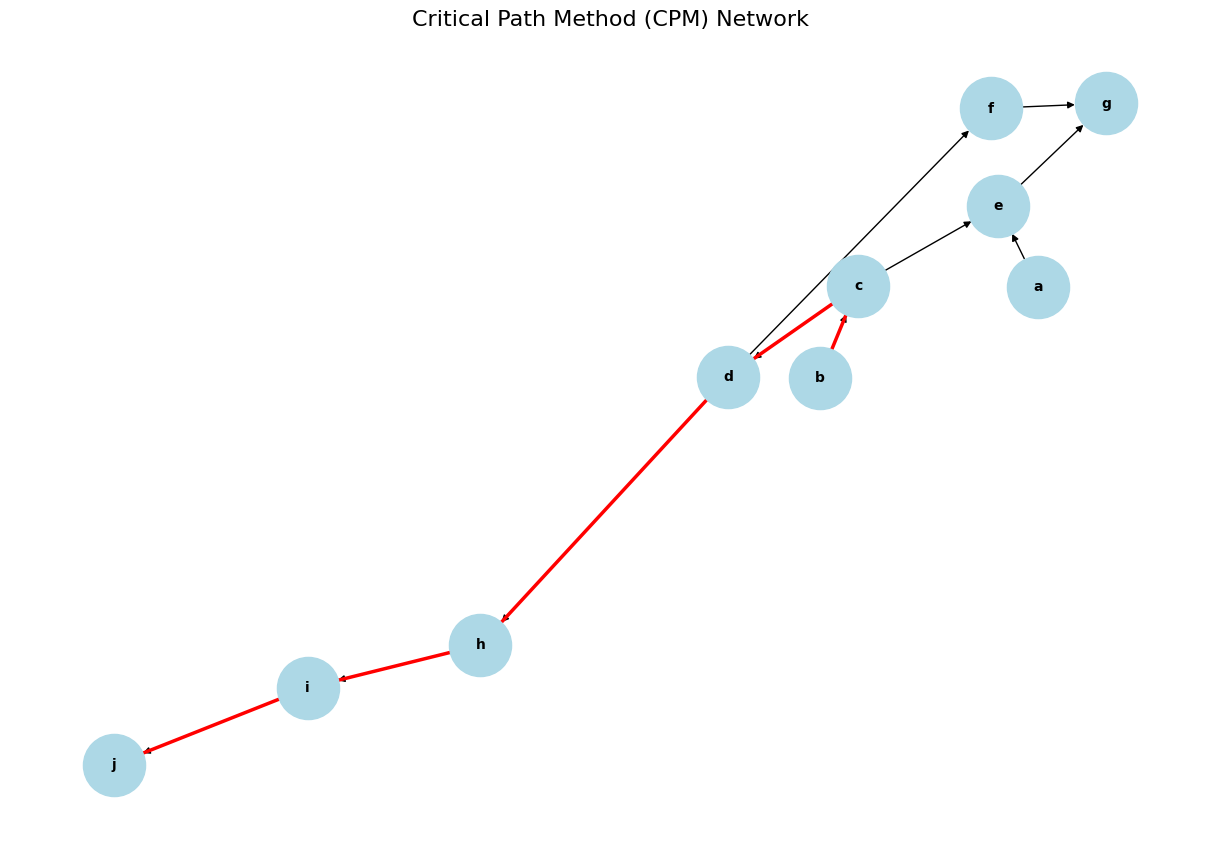

In [4]:


def pro_dur_cpm(df_pm):
    # Add the Estimate, Start, and End columns
    df_pm['Estimate'] = df_pm.apply(lambda row: math.ceil((row['Optimistic_a'] + row['Most_likely_m']*4 + row['Pessimistic_b'])/6), axis=1)
    df_pm['Start'] = 0
    df_pm['End'] = None
    
    # Add values to the columns
    for index, row in df_pm.iterrows():
        # Get the list of predecessors
        pred_list = row['Predecessor'].split(',')

        # When there is no predecessor
        if row['Predecessor'] == '-':
            start = 0
            end = start + row['Estimate']
            df_pm.at[index, 'Start'] = start
            df_pm.at[index, 'End'] = end

        # When there are one or multiple predecessors
        else:
            end_list = [df_pm.loc[x, 'End'] for x in pred_list]
            start = max(end_list)
            end = start + row['Estimate']
            df_pm.at[index, 'Start'] = start
            df_pm.at[index, 'End'] = end

    # Identify the activities that are not predecessors of any activity (terminals)
    all_predecessors = ','.join(df_pm['Predecessor'].tolist())
    activities = df_pm.index.tolist()
    terminals = [x for x in activities if x not in all_predecessors]

    # Find the project duration
    project_end_times = [df_pm.loc[x, 'End'] for x in terminals]
    project_duration = max(project_end_times)

    # Calculate the critical path
    critical_path = []
    latest_end = project_duration
    for activity in reversed(df_pm.index):
        if df_pm.loc[activity, 'End'] == latest_end:
            critical_path.insert(0, activity)
            latest_end = df_pm.loc[activity, 'Start']

    return project_duration, critical_path, df_pm

def plot_cpm(df_pm, critical_path):
    # Create a directed graph
    G = nx.DiGraph()

    # Add edges with dependencies
    for index, row in df_pm.iterrows():
        preds = row['Predecessor'].split(',')
        if row['Predecessor'] != '-':
            for pred in preds:
                G.add_edge(pred, index)

    # Plot the graph
    pos = nx.spring_layout(G)
    plt.figure(figsize=(12, 8))

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=10, font_weight='bold')
    
    # Highlight the critical path
    critical_edges = [(critical_path[i], critical_path[i+1]) for i in range(len(critical_path)-1)]
    nx.draw_networkx_edges(G, pos, edgelist=critical_edges, edge_color='red', width=2.5)

    # Add title
    plt.title("Critical Path Method (CPM) Network", fontsize=16)
    plt.show()

# Example data
data = {
    'Activity': activities,
    'Optimistic_a': optimistic,
    'Most_likely_m': likely,
    'Pessimistic_b': pessimistic,
    'Predecessor': predecessor
}

# Create a DataFrame
df_pm = pd.DataFrame(data)
df_pm.set_index('Activity', inplace=True)

# Calculate project duration and plot
project_duration, critical_path, updated_df = pro_dur_cpm(df_pm)
print("Project Duration:", project_duration)
print("Critical Path:", critical_path)

# Plot CPM
plot_cpm(updated_df, critical_path)


In [5]:
# project duration
print('The project duration as from the CPM is: '+str(pro_dur_cpm(df_pm)))
df_pm
     


The project duration as from the CPM is: (708, ['b', 'c', 'd', 'h', 'i', 'j'],           Optimistic_a  Most_likely_m  Pessimistic_b Predecessor  Estimate  \
Activity                                                                     
a                  135            150            180           -       153   
b                  160            180            220           -       184   
c                   15             30             45           b        30   
d                  105            120            140           c       121   
e                  100            120            135         a,c       120   
f                   40             60             70           d        59   
g                   30             60             75         e,f        58   
h                  140            150            185           d       155   
i                  110            120            145           h       123   
j                   85             90            125           

,Optimistic_a,Most_likely_m,Pessimistic_b,Predecessor,Estimate,Start,End
Activity,,,,,,,
a,135,150,180,-,153,0,153
b,160,180,220,-,184,0,184
c,15,30,45,b,30,184,214
d,105,120,140,c,121,214,335
e,100,120,135,"a,c",120,214,334
f,40,60,70,d,59,335,394
g,30,60,75,"e,f",58,394,452
h,140,150,185,d,155,335,490
i,110,120,145,h,123,490,613
